In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from PIL import Image
import cv2

In [ ]:
%pip install datasets


In [3]:
from pathlib import Path
import sys

# Make imports work whether Jupyter starts in the project root or notebooks/.
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "data" / "data_loader.py").is_file()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.data_loader import load_cub_dataset


d:\preprocess_dl\from-pixels-to-language\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
train_dataset, test_dataset = load_cub_dataset()

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

d:\preprocess_dl\from-pixels-to-language\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Access\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\preprocess_dl\from-pixels-to-language\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_h

Training samples: 5994
Test samples: 5794


In [5]:
print("Training columns:")
print(train_dataset.column_names)

print("\nTraining features:")
print(train_dataset.features)

print("\nFirst training record:")
print(train_dataset[0])

Training columns:
['image', 'description', 'label', 'file_name', 'id']

Training features:
{'image': Image(mode=None, decode=True), 'description': Value('string'), 'label': ClassLabel(names=['Black footed Albatross', 'Laysan Albatross', 'Sooty Albatross', 'Groove billed Ani', 'Crested Auklet', 'Least Auklet', 'Parakeet Auklet', 'Rhinoceros Auklet', 'Brewer Blackbird', 'Red winged Blackbird', 'Rusty Blackbird', 'Yellow headed Blackbird', 'Bobolink', 'Indigo Bunting', 'Lazuli Bunting', 'Painted Bunting', 'Cardinal', 'Spotted Catbird', 'Gray Catbird', 'Yellow breasted Chat', 'Eastern Towhee', 'Chuck will Widow', 'Brandt Cormorant', 'Red faced Cormorant', 'Pelagic Cormorant', 'Bronzed Cowbird', 'Shiny Cowbird', 'Brown Creeper', 'American Crow', 'Fish Crow', 'Black billed Cuckoo', 'Mangrove Cuckoo', 'Yellow billed Cuckoo', 'Gray crowned Rosy Finch', 'Purple Finch', 'Northern Flicker', 'Acadian Flycatcher', 'Great Crested Flycatcher', 'Least Flycatcher', 'Olive sided Flycatcher', 'Scissor ta

In [ ]:
for i in range(min(5, len(train_dataset))):
    sample = train_dataset[i]

    print(f"\nSample {i + 1}")
    for column, value in sample.items():
        if column == "image":
            print(column, ":", type(value))
        else:
            print(column, ":", repr(value)[:500])

In [ ]:

# Extract numeric labels from both splits
train_labels = train_dataset["label"]
test_labels = test_dataset["label"]

# Get species names from the dataset's ClassLabel feature
class_names = train_dataset.features["label"].names

print("Number of bird species:", len(class_names))
print("Number of training images:", len(train_labels))
print("Number of test images:", len(test_labels))
print("Number of unique training classes:", len(set(train_labels)))
print("Number of unique test classes:", len(set(test_labels)))


In [ ]:

# Calculate class frequencies
train_counts = pd.Series(train_labels).value_counts().sort_index()
test_counts = pd.Series(test_labels).value_counts().sort_index()

# Create a summary table
class_distribution = pd.DataFrame({
    "species": class_names,
    "train_count": [
        train_counts.get(i, 0) for i in range(len(class_names))
    ],
    "test_count": [
        test_counts.get(i, 0) for i in range(len(class_names))
    ]
})

class_distribution["total_count"] = (
    class_distribution["train_count"]
    + class_distribution["test_count"]
)

display(class_distribution.head(200))

In [ ]:

counts = class_distribution["train_count"]

print("Minimum images per species:", counts.min())
print("Maximum images per species:", counts.max())
print("Mean images per species:", round(counts.mean(), 2))
print("Median images per species:", counts.median())

if counts.min() > 0:
    print(
        "Max/min class ratio:",
        round(counts.max() / counts.min(), 2)
    )
else:
    print("At least one species has no training images.")


In [ ]:
num_images = min(12, len(train_dataset))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i in range(num_images):
    sample = train_dataset[i]
    img = sample["image"]
    label = sample["label"]

    axes[i].imshow(img)
    axes[i].set_title(class_names[label])
    axes[i].axis("off")

for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:



# Sort species by label order
train_plot = class_distribution.sort_values(
    "train_count", ascending=True
)

plt.figure(figsize=(14, 28))

plt.barh(
    train_plot["species"],
    train_plot["train_count"]
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Bird Species")

plt.xticks(range(0, int(train_plot["train_count"].max()) + 2, 5))
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


In [ ]:
# Note that this checks whether the images can be accessed and have valid dimensions
image_stats = []

for idx, sample in enumerate(train_dataset):
    try:
        img = sample["image"]

        if img is None:
            raise ValueError("Image is None")

        width, height = img.size

        if width <= 0 or height <= 0:
            raise ValueError("Invalid image dimensions")

        image_stats.append({
            "index": idx,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "mode": img.mode,
            "format": img.format,
            "valid": True
        })

    except Exception as e:
        image_stats.append({
            "index": idx,
            "width": None,
            "height": None,
            "aspect_ratio": None,
            "mode": None,
            "format": None,
            "valid": False
        })

image_df = pd.DataFrame(image_stats)

print("Total images:", len(image_df))
print("Valid images:", image_df["valid"].sum())
print("Invalid images:", (~image_df["valid"]).sum())

In [ ]:
valid_images = image_df[image_df["valid"]].copy()

print("Width statistics:")
print(valid_images["width"].describe())

print("\nHeight statistics:")
print(valid_images["height"].describe())

print("\nAspect ratio statistics:")
print(valid_images["aspect_ratio"].describe())

print("\nColor modes:")
print(valid_images["mode"].value_counts())

print("\nImage formats:")
print(valid_images["format"].value_counts())

In [ ]:

for idx in range(min(5, len(train_dataset))):
    try:
        img = train_dataset[idx]["image"]

        print(f"\nImage {idx}")
        print("Image type:", type(img))

        rgb = np.array(img.convert("RGB"))
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

        sharpness = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        print("Image size:", img.size)
        print("Sharpness:", sharpness)

    except Exception as e:
        print(f"Error for image {idx}: {type(e).__name__}: {e}")


In [28]:


quality_stats = []

for idx, sample in enumerate(train_dataset):
    try:
        img = sample["image"]

        if img is None:
            raise ValueError("Missing image")

        # Convert PIL image to RGB
        rgb = np.array(img.convert("RGB"))

        # Convert RGB to grayscale for sharpness and brightness
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

        height, width = gray.shape

        # Laplacian variance: lower values can indicate blur
        sharpness = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        # Average grayscale intensity
        brightness = gray.mean()

        # Standard deviation indicates intensity variation
        contrast = gray.std()

        quality_stats.append({
            "index": idx,
            "width": width,
            "height": height,
            "resolution": width * height,
            "sharpness": sharpness,
            "brightness": brightness,
            "contrast": contrast,
            "valid": True
        })

    except Exception as e:
        quality_stats.append({
            "index": idx,
            "width": None,
            "height": None,
            "resolution": None,
            "sharpness": None,
            "brightness": None,
            "contrast": None,
            "valid": False
        })

quality_df = pd.DataFrame(quality_stats)

print("Total images:", len(quality_df))
print("Failed image checks:", (~quality_df["valid"]).sum())

display(
    quality_df.loc[quality_df["valid"]].describe().round(2)
)


Total images: 5994
Failed image checks: 0


,index,width,height,resolution,sharpness,brightness,contrast
count,5994.00,5994.00,5994.00,5994.00,5994.00,5994.00,5994.00
mean,2996.50,467.62,386.25,179397.96,1400.23,124.35,45.36
std,1730.46,64.52,70.96,32166.73,1965.04,32.02,14.22
min,0.00,121.00,120.00,19460.00,7.97,20.98,9.70
25%,1498.25,492.00,333.00,166500.00,410.21,103.91,34.98
50%,2996.50,500.00,375.00,178500.00,817.31,123.26,44.29
75%,4494.75,500.00,435.00,195000.00,1637.49,144.09,54.42
max,5993.00,500.00,500.00,250000.00,53215.03,244.11,106.25


In [ ]:

print("Width range:", quality_df["width"].min(),
      "to", quality_df["width"].max())

print("Height range:", quality_df["height"].min(),
      "to", quality_df["height"].max())

print("Invalid images:", (~quality_df["valid"]).sum())

print("\nImages with the smallest sharpness values:")
display(
    quality_df.nsmallest(10, "sharpness")[
        ["index", "width", "height", "sharpness",
         "brightness", "contrast", "valid"]
    ]
)


# Image EDA

Goal: understand the images in **both** splits. The findings will decide the resize, normalization, validation split and augmentation for classification (done in the preprocessing step).

One pass over all 11,788 images computes every statistic used below and saves it to `outputs/eda/image_stats.csv`. The first run takes a few minutes; later runs load the CSV instantly (delete the file to recompute). This replaces the earlier train-only quality cells.

In [19]:
STATS_PATH = project_root / "outputs" / "eda" / "image_stats.csv"
STATS_SIZE = 224  # channel mean/std are measured at the size the model will see


def dhash(img, size=8):
    """Perceptual hash: near-identical images get the same 64-bit value."""
    gray = img.convert("L").resize((size + 1, size), Image.BILINEAR)
    pixels = np.asarray(gray, dtype=np.int16)
    bits = (pixels[:, 1:] > pixels[:, :-1]).flatten()
    return f"{int(''.join('1' if b else '0' for b in bits), 2):016x}"


def compute_image_stats(img):
    rgb = np.asarray(img.convert("RGB"))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

    # Largest R-G / G-B difference on a small copy: ~0 means a grayscale photo
    small = cv2.resize(rgb, (64, 64), interpolation=cv2.INTER_AREA).astype(np.int16)
    channel_diff = max(
        np.abs(small[..., 0] - small[..., 1]).max(),
        np.abs(small[..., 1] - small[..., 2]).max(),
    )

    resized = cv2.resize(rgb, (STATS_SIZE, STATS_SIZE), interpolation=cv2.INTER_AREA) / 255.0

    return {
        "width": img.width,
        "height": img.height,
        "mode": img.mode,
        "sharpness": cv2.Laplacian(gray, cv2.CV_64F).var(),
        "brightness": gray.mean(),
        "contrast": gray.std(),
        "saturation": hsv[..., 1].mean() / 255,
        "channel_diff": channel_diff,
        "dhash": dhash(img),
        **{f"mean_{c}": resized[..., i].mean() for i, c in enumerate("rgb")},
        **{f"sqmean_{c}": (resized[..., i] ** 2).mean() for i, c in enumerate("rgb")},
    }


if STATS_PATH.exists():
    img_stats = pd.read_csv(STATS_PATH, dtype={"dhash": str})
    print("Loaded cached statistics from", STATS_PATH)
else:
    rows = []
    for split, dataset in [("train", train_dataset), ("test", test_dataset)]:
        for idx, sample in enumerate(dataset):
            row = {"split": split, "idx": idx, "label": sample["label"], "error": None}
            try:
                row.update(compute_image_stats(sample["image"]))
            except Exception as e:
                row["error"] = f"{type(e).__name__}: {e}"
            rows.append(row)
            if (idx + 1) % 1000 == 0:
                print(f"{split}: {idx + 1}/{len(dataset)}")

    img_stats = pd.DataFrame(rows)
    STATS_PATH.parent.mkdir(parents=True, exist_ok=True)
    img_stats.to_csv(STATS_PATH, index=False)
    print("Saved statistics to", STATS_PATH)

img_stats["aspect_ratio"] = img_stats["width"] / img_stats["height"]
img_stats["short_side"] = img_stats[["width", "height"]].min(axis=1)
img_stats["species"] = img_stats["label"].map(lambda label: class_names[label])

print("Images:", img_stats["split"].value_counts().to_dict())
print("Failed to decode (corrupted):", img_stats["error"].notna().sum())

train: 1000/5994
train: 2000/5994
train: 3000/5994
train: 4000/5994
train: 5000/5994
test: 1000/5794
test: 2000/5794
test: 3000/5794
test: 4000/5794
test: 5000/5794
Saved statistics to d:\preprocess_dl\from-pixels-to-language\outputs\eda\image_stats.csv
Images: {'train': 5994, 'test': 5794}
Failed to decode (corrupted): 0


In [20]:
def show_images(rows, title=None, ncols=6, size=2.6, suptitle=None):
    """Plot dataset images from rows of img_stats (needs 'split' and 'idx' columns)."""
    rows = list(rows.itertuples(index=False))
    if not rows:
        print("Nothing to show.")
        return
    nrows = -(-len(rows) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, rows):
        dataset = train_dataset if row.split == "train" else test_dataset
        ax.imshow(dataset[int(row.idx)]["image"].convert("RGB"))
        ax.set_title(title(row) if title else f"{row.split} #{row.idx}", fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

## 1. Image sizes and aspect ratios

Decides the input size and the resize/crop strategy.

split                  test    train
width        count  5794.00  5994.00
             mean    468.16   467.62
             std      63.31    64.52
             min     140.00   121.00
             25%     498.00   492.00
             50%     500.00   500.00
             75%     500.00   500.00
             max     500.00   500.00
height       count  5794.00  5994.00
             mean    385.80   386.25
             std      70.82    70.96
             min     134.00   120.00
             25%     333.00   333.00
             50%     375.00   375.00
             75%     432.75   435.00
             max     500.00   500.00
aspect_ratio count  5794.00  5994.00
             mean      1.26     1.26
             std       0.29     0.29
             min       0.38     0.49
             25%       1.09     1.07
             50%       1.33     1.33
             75%       1.50     1.50
             max       2.56     3.60
short_side   count  5794.00  5994.00
             mean    362.77   363.93
             std      51.69    53.14
             min     134.00   120.00
             25%     333.00   333.00
             50%     357.00   357.00
             75%     388.00   391.00
             max     500.00   500.00

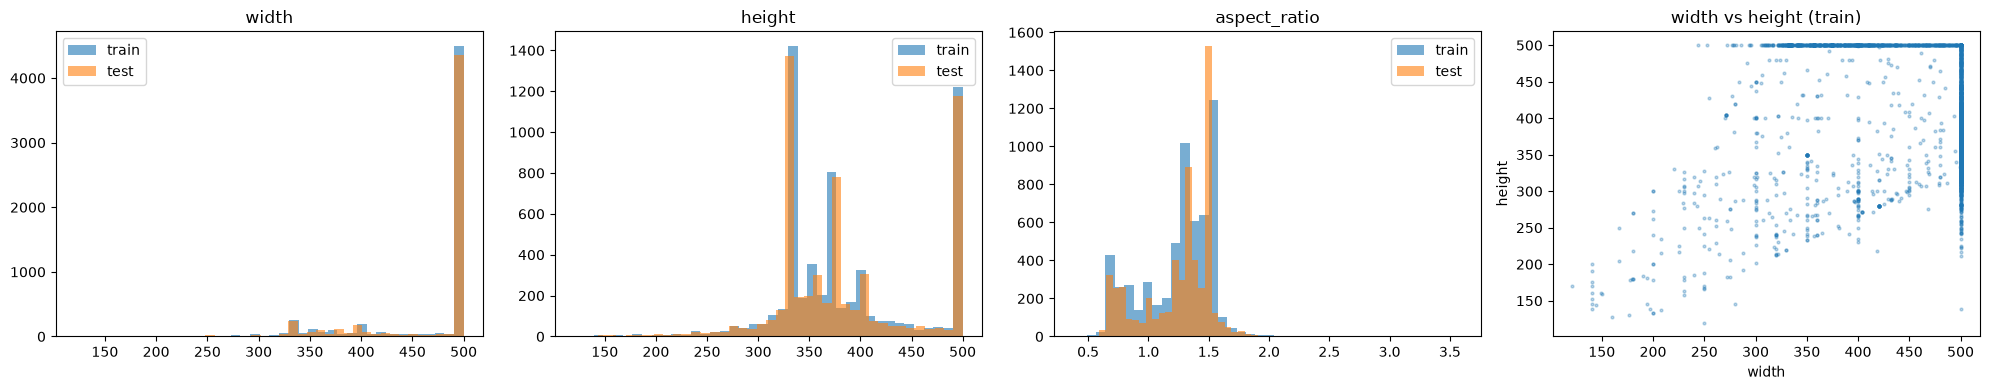

Images whose longest side is 500 px: 92.7%
Landscape (aspect > 1.05): 76.1%
Portrait (aspect < 0.95): 18.7%
Short side < 150 px: {'train': 21, 'test': 8}
Short side < 224 px: {'train': 74, 'test': 74}
Short side < 256 px: {'train': 149, 'test': 142}


In [21]:
display(
    img_stats.groupby("split")[["width", "height", "aspect_ratio", "short_side"]]
    .describe().T.round(2)
)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes[:3], ["width", "height", "aspect_ratio"]):
    for split in ["train", "test"]:
        ax.hist(img_stats.loc[img_stats["split"] == split, col], bins=40, alpha=0.6, label=split)
    ax.set_title(col)
    ax.legend()

train_stats = img_stats[img_stats["split"] == "train"]
axes[3].scatter(train_stats["width"], train_stats["height"], s=4, alpha=0.3)
axes[3].set_xlabel("width")
axes[3].set_ylabel("height")
axes[3].set_title("width vs height (train)")
plt.tight_layout()
plt.show()

longest = img_stats[["width", "height"]].max(axis=1)
print(f"Images whose longest side is 500 px: {(longest == 500).mean() * 100:.1f}%")
print(f"Landscape (aspect > 1.05): {(img_stats['aspect_ratio'] > 1.05).mean() * 100:.1f}%")
print(f"Portrait (aspect < 0.95): {(img_stats['aspect_ratio'] < 0.95).mean() * 100:.1f}%")
for threshold in [150, 224, 256]:
    counts = img_stats[img_stats["short_side"] < threshold]["split"].value_counts().to_dict()
    print(f"Short side < {threshold} px: {counts}")

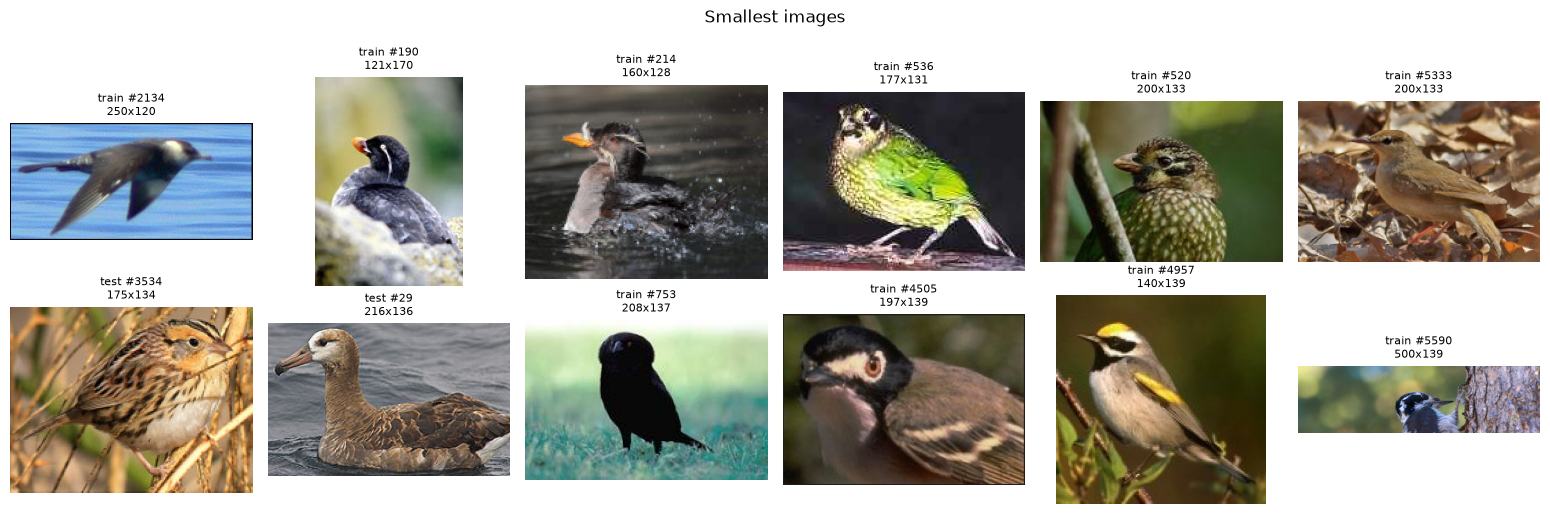

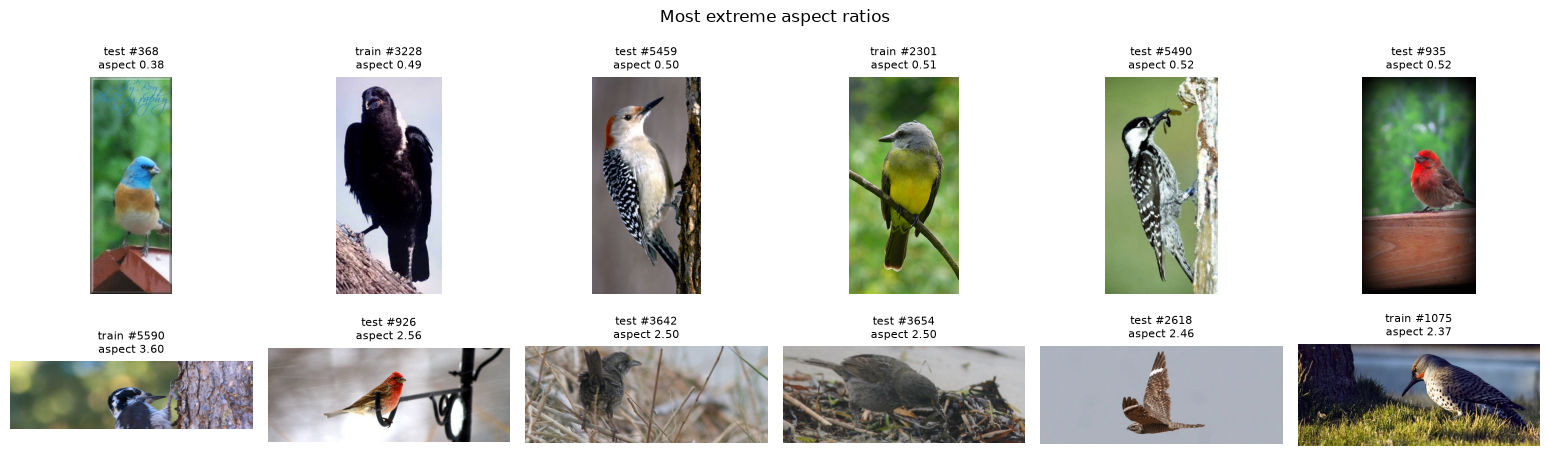

In [22]:
# Smallest images: these get upscaled to 224 px and may look blurry
show_images(
    img_stats.nsmallest(12, "short_side"),
    title=lambda r: f"{r.split} #{r.idx}\n{r.width}x{r.height}",
    suptitle="Smallest images",
)

# Most extreme aspect ratios: a center crop may cut the bird off
extreme = pd.concat([img_stats.nsmallest(6, "aspect_ratio"), img_stats.nlargest(6, "aspect_ratio")])
show_images(
    extreme,
    title=lambda r: f"{r.split} #{r.idx}\naspect {r.aspect_ratio:.2f}",
    suptitle="Most extreme aspect ratios",
)

## 2. Color modes and grayscale images

Grayscale images need converting to 3 channels for the CNN, and they have no color target for colorization (phase 2).

split,test,train
mode,,
L,4,4
RGB,5790,5990


Grayscale photos (any mode): {'train': 5, 'test': 4}


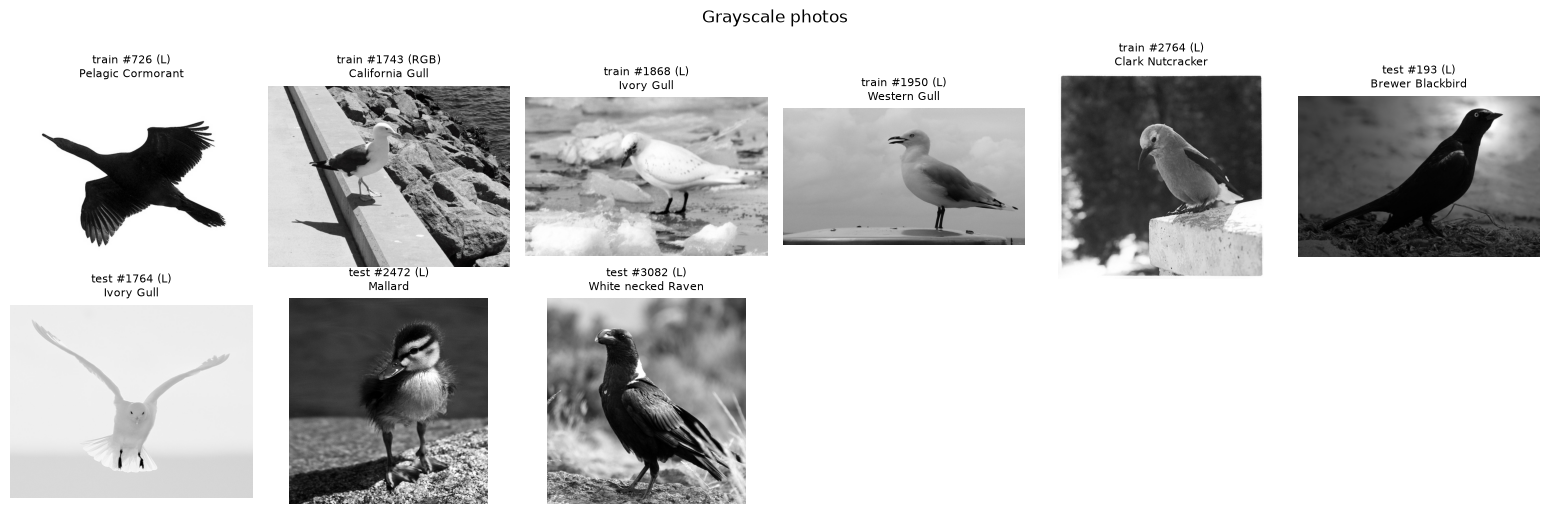

Color photos with very low saturation: {'test': 96, 'train': 95}


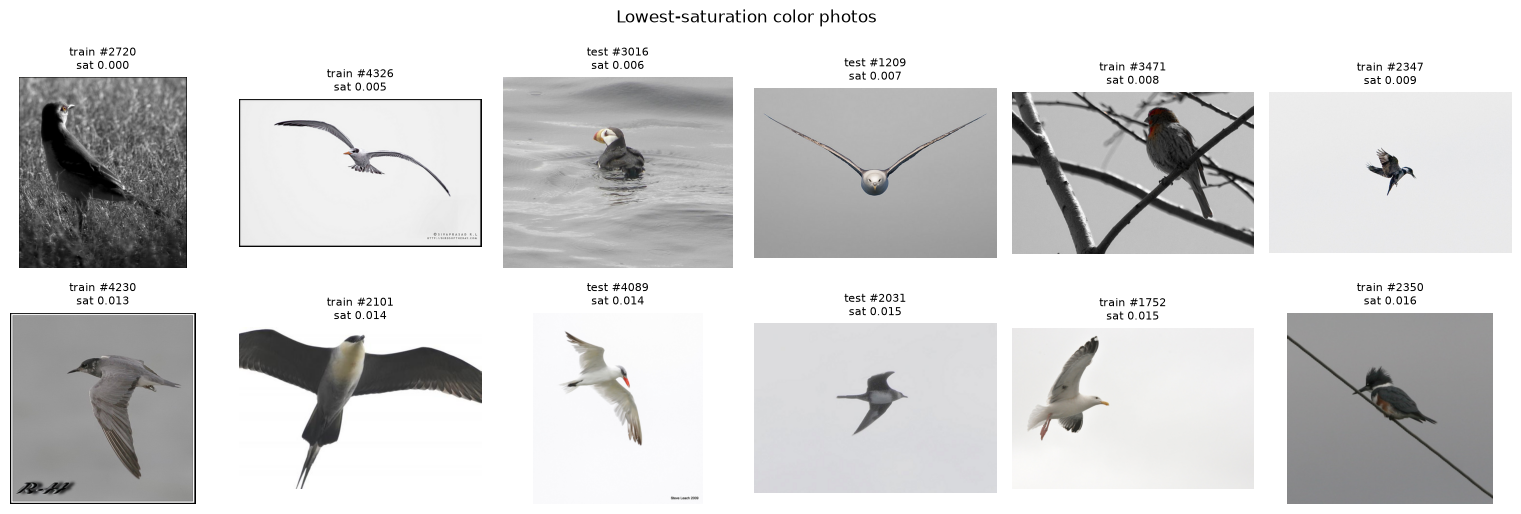

In [23]:
display(pd.crosstab(img_stats["mode"], img_stats["split"]))

# channel_diff < 5 (out of 255): R, G and B are practically identical, even if stored as RGB
grayscale = img_stats[img_stats["channel_diff"] < 5]
print("Grayscale photos (any mode):", grayscale["split"].value_counts().to_dict())
show_images(
    grayscale,
    title=lambda r: f"{r.split} #{r.idx} ({r.mode})\n{r.species}",
    suptitle="Grayscale photos",
)

low_saturation = img_stats[(img_stats["saturation"] < 0.05) & (img_stats["channel_diff"] >= 5)]
print("Color photos with very low saturation:", low_saturation["split"].value_counts().to_dict())
show_images(
    low_saturation.nsmallest(12, "saturation"),
    title=lambda r: f"{r.split} #{r.idx}\nsat {r.saturation:.3f}",
    suptitle="Lowest-saturation color photos",
)

## 3. Image quality: sharpness, brightness, contrast

- **Sharpness**: variance of the Laplacian. Low values suggest blur.
- **Brightness**: mean gray level (0 black, 255 white).
- **Contrast**: standard deviation of the gray levels.

These scores only flag candidates; look at the images before deciding anything.

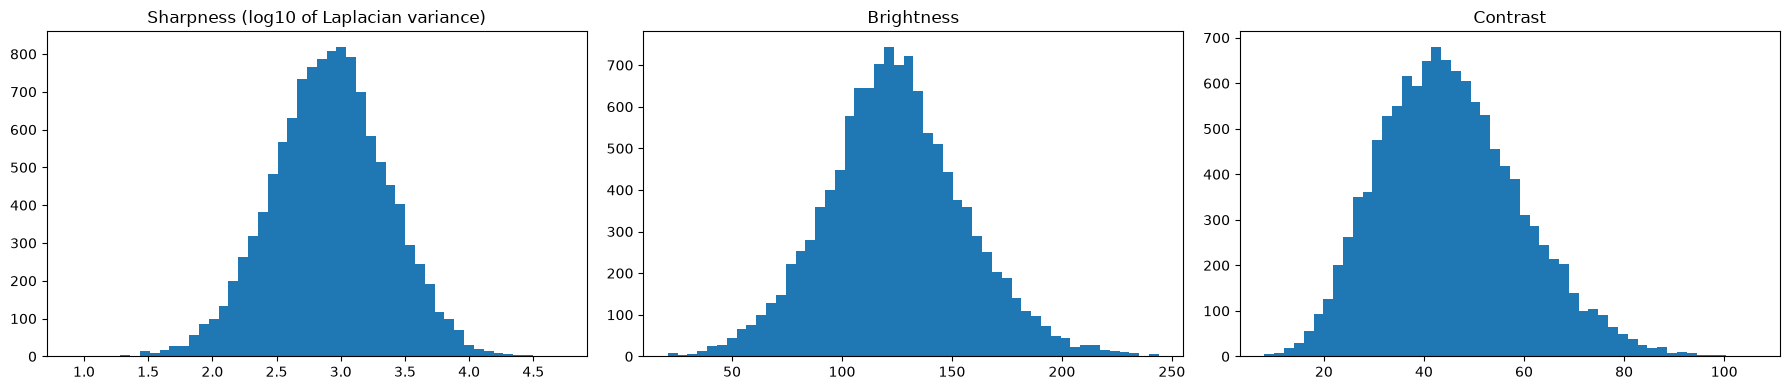

,sharpness,brightness,contrast,saturation
count,11788.00,11788.00,11788.00,11788.00
mean,1380.14,124.38,45.41,0.32
std,1869.68,31.98,14.11,0.16
min,7.97,20.79,8.12,0.00
25%,411.70,103.94,35.16,0.19
50%,824.93,123.37,44.28,0.30
75%,1625.07,144.28,54.41,0.42
max,53215.03,244.11,106.25,0.95


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(np.log10(img_stats["sharpness"]), bins=50)
axes[0].set_title("Sharpness (log10 of Laplacian variance)")
axes[1].hist(img_stats["brightness"], bins=50)
axes[1].set_title("Brightness")
axes[2].hist(img_stats["contrast"], bins=50)
axes[2].set_title("Contrast")
plt.tight_layout()
plt.show()

display(img_stats[["sharpness", "brightness", "contrast", "saturation"]].describe().round(2))

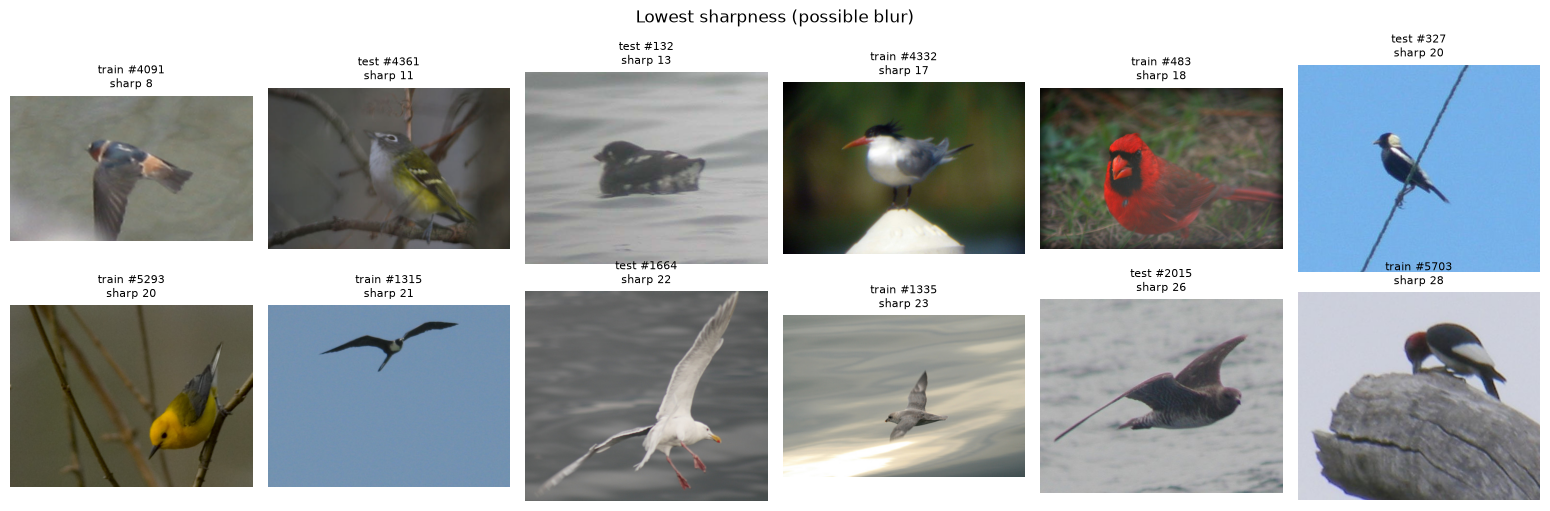

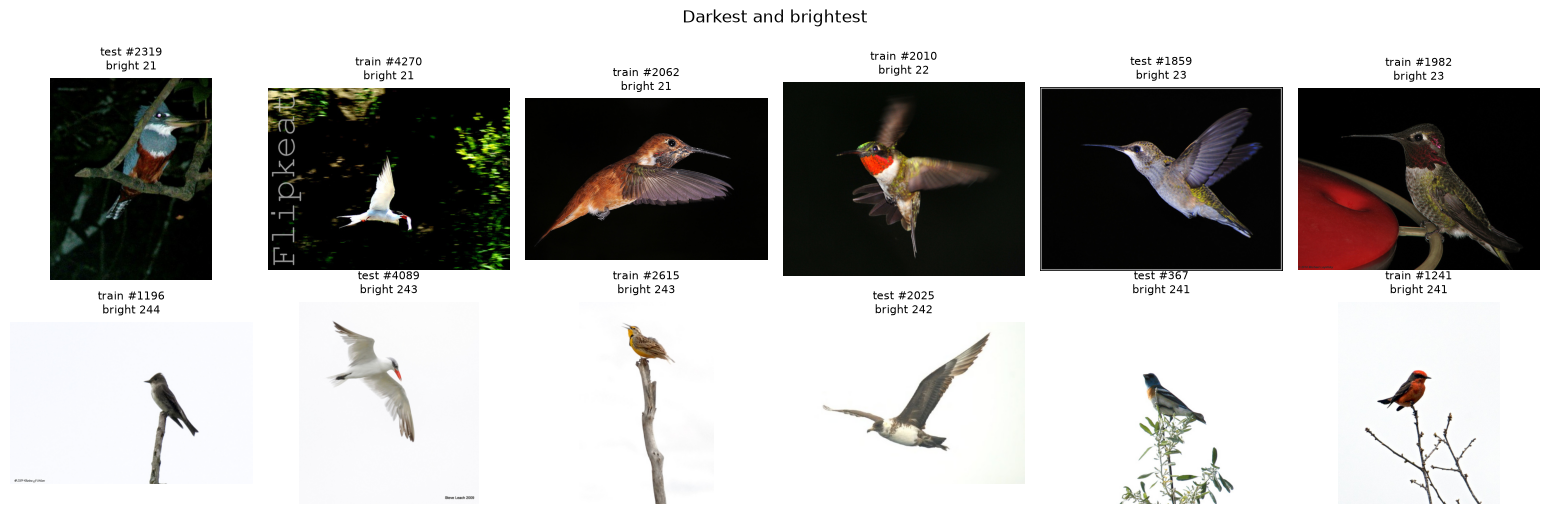

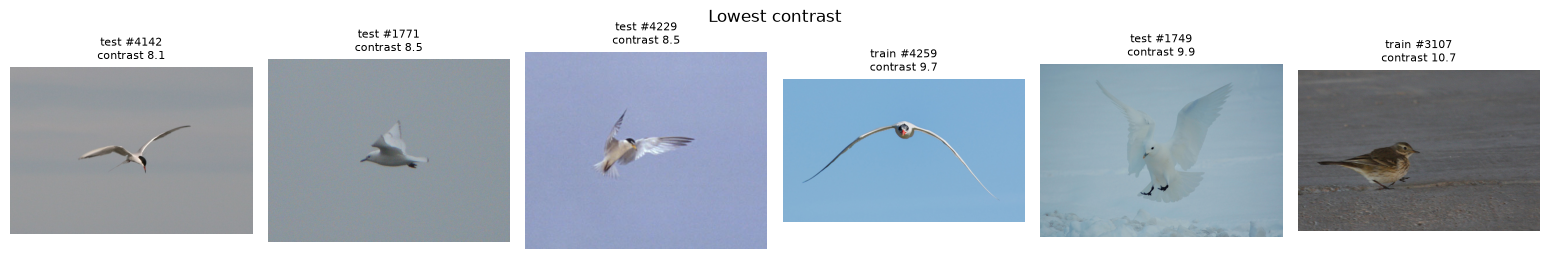

In [25]:
show_images(
    img_stats.nsmallest(12, "sharpness"),
    title=lambda r: f"{r.split} #{r.idx}\nsharp {r.sharpness:.0f}",
    suptitle="Lowest sharpness (possible blur)",
)
show_images(
    pd.concat([img_stats.nsmallest(6, "brightness"), img_stats.nlargest(6, "brightness")]),
    title=lambda r: f"{r.split} #{r.idx}\nbright {r.brightness:.0f}",
    suptitle="Darkest and brightest",
)
show_images(
    img_stats.nsmallest(6, "contrast"),
    title=lambda r: f"{r.split} #{r.idx}\ncontrast {r.contrast:.1f}",
    suptitle="Lowest contrast",
)

## 4. Duplicate images

Images with the same perceptual hash are near-identical. A duplicate shared by train and test is **data leakage**: the model is tested on a photo it trained on.

Duplicate groups: 6
Groups spanning train and test (leakage): 2


,dhash,split,idx,species,width,height
9258,56767a5ad2c4648c,test,3264,Brewer Sparrow,500,333
9270,56767a5ad2c4648c,test,3276,Brewer Sparrow,500,333
8362,5c5c7cfc1c131f1b,test,2368,Red legged Kittiwake,140,179
8368,5c5c7cfc1c131f1b,test,2374,Red legged Kittiwake,392,500
5315,723218d94d952c0a,train,5315,Swainson Warbler,500,333
5333,723218d94d952c0a,train,5333,Swainson Warbler,200,133
11109,734361e0b0342787,test,5115,Prothonotary Warbler,500,375
5277,734361e0b0342787,train,5277,Prothonotary Warbler,500,375
6655,b4a64e8e8e0d5c5b,test,661,Bronzed Cowbird,375,500
774,b4a64e8e8e0d5c5b,train,774,Bronzed Cowbird,375,500


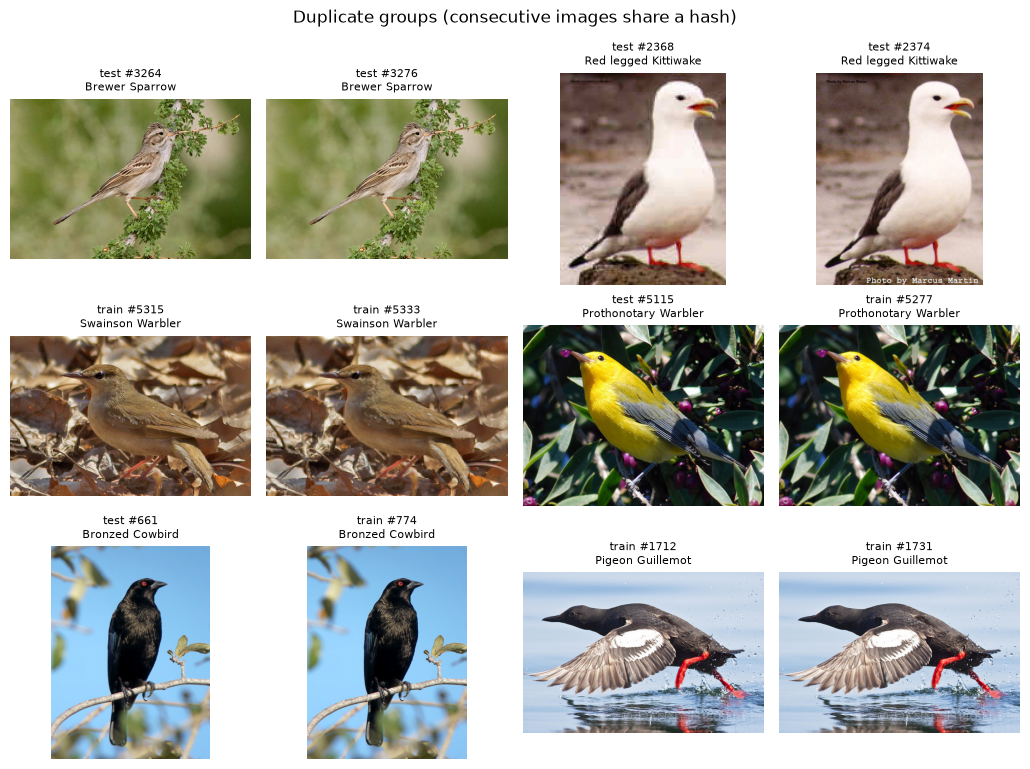

In [26]:
duplicates = img_stats[img_stats.duplicated("dhash", keep=False)].sort_values(["dhash", "split", "idx"])
dup_groups = duplicates.groupby("dhash")["split"].agg(list)

print("Duplicate groups:", len(dup_groups))
print("Groups spanning train and test (leakage):", dup_groups.map(lambda s: len(set(s)) > 1).sum())
display(duplicates[["dhash", "split", "idx", "species", "width", "height"]])

show_images(
    duplicates,
    title=lambda r: f"{r.split} #{r.idx}\n{r.species}",
    ncols=4,
    suptitle="Duplicate groups (consecutive images share a hash)",
)

## 5. Channel mean and standard deviation

Normalization subtracts the mean and divides by the standard deviation of each color channel. Pretrained models expect the ImageNet values, so compare them with this dataset's.

In [27]:
train_stats = img_stats[(img_stats["split"] == "train") & img_stats["error"].isna()]

# Every image was resized to 224x224, so each one has the same weight
dataset_mean = np.array([train_stats[f"mean_{c}"].mean() for c in "rgb"])
dataset_std = np.sqrt(
    np.array([train_stats[f"sqmean_{c}"].mean() for c in "rgb"]) - dataset_mean ** 2
)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

display(pd.DataFrame(
    {
        "CUB train mean": dataset_mean.round(3),
        "ImageNet mean": IMAGENET_MEAN,
        "CUB train std": dataset_std.round(3),
        "ImageNet std": IMAGENET_STD,
    },
    index=["R", "G", "B"],
))

,CUB train mean,ImageNet mean,CUB train std,ImageNet std
R,0.486,0.485,0.228,0.229
G,0.499,0.456,0.223,0.224
B,0.432,0.406,0.262,0.225


,images,aspect_min,aspect_max,mean_padding_pct,share_%
shape,,,,,
Tall portrait,570,0.38,0.67,34.30,4.84
Portrait,1633,0.67,0.95,21.29,13.85
Square,618,0.95,1.05,1.46,5.24
Landscape,4294,1.05,1.40,21.59,36.43
Wide landscape,4641,1.40,1.98,33.32,39.37
Panorama,32,2.00,3.60,53.96,0.27


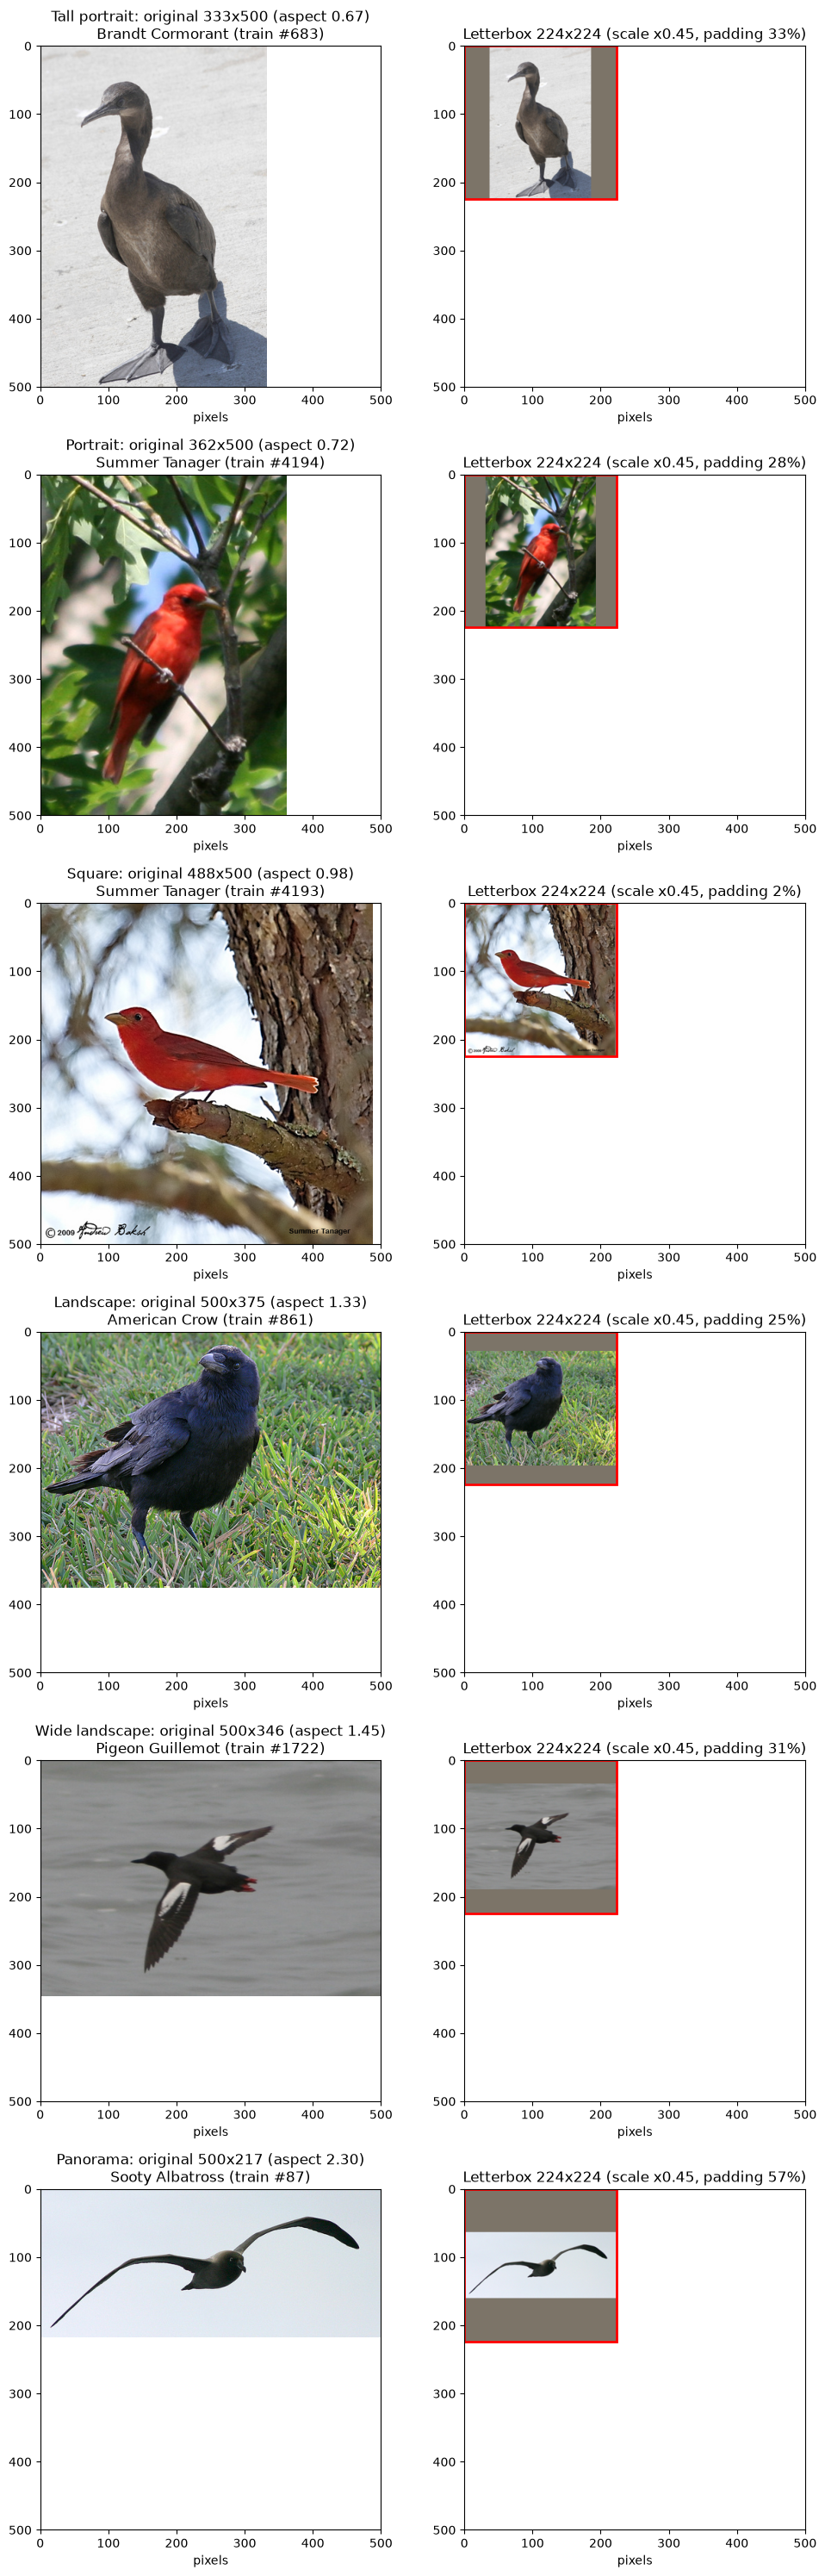

In [30]:
from PIL import Image

PAD_COLOR = (124, 116, 104)  # ImageNet mean in 0-255; becomes ~0 after normalization
TARGET_SIZE = 224


def letterbox(img, size=TARGET_SIZE, fill=PAD_COLOR):
    """Resize so the longest side is `size`, then pad to a square. Nothing is cut off."""
    img = img.convert("RGB")
    scale = size / max(img.size)
    new_w, new_h = round(img.width * scale), round(img.height * scale)
    resized = img.resize((new_w, new_h), Image.BICUBIC)

    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(resized, ((size - new_w) // 2, (size - new_h) // 2))  # center it
    return canvas


# Group images by shape (aspect ratio = width / height)
SHAPES = [
    ("Tall portrait", 0.0, 0.67),
    ("Portrait", 0.67, 0.95),
    ("Square", 0.95, 1.05),
    ("Landscape", 1.05, 1.4),
    ("Wide landscape", 1.4, 2.0),
    ("Panorama", 2.0, float("inf")),
]
shape_names = [name for name, _, _ in SHAPES]
img_stats["shape"] = pd.cut(
    img_stats["aspect_ratio"],
    bins=[low for _, low, _ in SHAPES] + [SHAPES[-1][2]],
    labels=shape_names,
    right=False,
)

# Share of the 224x224 canvas that becomes padding: 1 - short side / long side
img_stats["padding_%"] = (1 - img_stats["short_side"] / img_stats[["width", "height"]].max(axis=1)) * 100

summary = img_stats.groupby("shape", observed=False).agg(
    images=("idx", "size"),
    aspect_min=("aspect_ratio", "min"),
    aspect_max=("aspect_ratio", "max"),
    mean_padding_pct=("padding_%", "mean"),
)
summary["share_%"] = summary["images"] / len(img_stats) * 100
display(summary.round(2))

# One random training example of each shape
examples = [
    img_stats[(img_stats["split"] == "train") & (img_stats["shape"] == name)].sample(1, random_state=42)
    for name in shape_names
]

# Both panels use the same pixel scale (0-500), so the output really looks smaller.
# The red square is the 224x224 output: inside it is image or padding, outside is empty plot.
fig, axes = plt.subplots(len(examples), 2, figsize=(10, 5 * len(examples)))
for (ax_orig, ax_box), (name, row) in zip(axes, zip(shape_names, examples)):
    row = row.iloc[0]
    img = train_dataset[int(row["idx"])]["image"].convert("RGB")
    boxed = letterbox(img)
    scale = TARGET_SIZE / max(img.size)

    ax_orig.imshow(img, extent=(0, img.width, img.height, 0))
    ax_orig.set_title(f"{name}: original {img.width}x{img.height} (aspect {row['aspect_ratio']:.2f})\n"
                      f"{row['species']} (train #{row['idx']})")
    ax_box.imshow(boxed, extent=(0, TARGET_SIZE, TARGET_SIZE, 0))
    ax_box.add_patch(plt.Rectangle((0, 0), TARGET_SIZE, TARGET_SIZE,
                                   fill=False, edgecolor="red", linewidth=2))
    ax_box.set_title(f"Letterbox {TARGET_SIZE}x{TARGET_SIZE} (scale x{scale:.2f}, "
                     f"padding {row['padding_%']:.0f}%)")

    for ax in (ax_orig, ax_box):
        ax.set_xlim(0, 500)
        ax.set_ylim(500, 0)
        ax.set_xlabel("pixels")

plt.tight_layout()
plt.show()


## Image EDA: findings

Numbers measured on all 11,788 images. Rows marked *(check)* depend on looking at the image grids above.

| Question | Finding | Decision |
|---|---|---|
| Corrupted files | 0 images fail to decode. | Nothing to remove. |
| Class balance | Train: 29-30 images per species (balanced). Test: 11-30 per species. | No class weights or oversampling. Report macro-averaged metrics so small test classes count equally. |
| Image size | Longest side is 500 px for ~93% of images; median 500x375, median short side 357 px. Short side as small as 120 px; 74 images per split have a short side under 224 px. Train and test have the same size distribution. | **Input size 224x224.** (1) The pretrained models were trained on ImageNet at 224x224 (resize 256, crop 224), so their features match objects at this scale. (2) ResNet-style CNNs downsample by 32, and 224 / 32 = 7 gives a clean 7x7 final feature map. (3) Cost grows with the number of pixels: 448x448 costs 4x more, which matters on a free T4 GPU. (4) With a median short side of 357 px, shrinking to 224 loses little detail. Small images are upscaled; keep them. |
| Aspect ratio | Median 1.33 (4:3); 76% landscape, 19% portrait; range 0.38-3.6. Images are not square. | Images must be made the same size without distorting or cutting the bird (see resize method). |
| Resize method | Compared on real images (typical 4:3, widest, tallest): **stretching** to a square distorts 76% of images by more than 25% (worst 3.6x); stretching to the mean size (468x386) still distorts 26% by more than 25%, squashes portraits and costs 3.6x more pixels. **Resize + center crop** keeps shapes but can remove key features: on the tallest image (White-necked Raven) it cuts off the head and the white neck patch the species is named after. **Letterbox** never distorts or cuts the bird; the cost is padding (25.8% of the canvas on average). | **Letterbox to 224x224**: resize so the longest side is 224, then pad to a square with the ImageNet mean color (124, 116, 104), which becomes ~0 after normalization. Experiment for tuning: a 4:3 canvas (288x216) reduces padding to 15.7% at about the same cost. |
| Small birds in large scenes | When the bird is small in the photo, it is only ~50 px wide after resizing to 224, and fine details (eye rings, wing bars) are hard to see. | Known limitation of fixed-size input. Published CUB results often use 448x448 for this reason, so state the input size when benchmarking. Possible experiments: a larger input size, or mild random zoom-in during training. |
| Color mode | 8 files are grayscale (`L`): 4 train, 4 test. 1 more grayscale photo is stored as RGB (train). | Convert everything to RGB. For colorization (phase 2), exclude grayscale photos: they have no color target. |
| Low saturation | 95 train and 96 test color photos are almost colorless (mean saturation < 0.05: gray birds, snow, water). | Keep: they are real color photos. |
| Sharpness / brightness / contrast | Wide range (sharpness 8 to 53,000). Low scores mostly flag soft backgrounds or dark scenes. *(check)* the grids. | Keep all images unless a grid shows one that is unusable. Brightness/contrast jitter covers lighting differences. |
| Duplicates | 6 near-identical pairs, all within the same species (some are the same photo at a different size). 2 pairs are shared by train and test (leakage). *(check)* the duplicate grid. | When splitting: drop the training copy of train/test duplicates (2) and the second copy of duplicates inside train (2). |
| Channel statistics | CUB train mean (0.486, 0.499, 0.432), std (0.228, 0.223, 0.262); ImageNet mean (0.485, 0.456, 0.406), std (0.229, 0.224, 0.225). | Use the ImageNet values for every model: pretrained models require them, and they are close to CUB's, so the from-scratch model can share the same pipeline. |
| Overfitting risk | Only ~30 training images per species, and species differ in small details (fine-grained). | Preprocessing must include augmentation and a validation split taken from train (next step). |

# Caption EDA

Goal: understand the `description` field before building the captioning model. The findings decide:

- how to split and clean the captions
- the vocabulary size (minimum word frequency)
- the maximum caption length

Only the text columns are read here, so these cells are fast (no image decoding).

## 1. Raw format of the `description` field

In [7]:
# Look at the raw strings first, so the splitting rule is based on what is really there
class_names = train_dataset.features["label"].names

for i in range(2):
    print(f"Record {i} ({class_names[train_dataset[i]['label']]}):")
    print(repr(train_dataset["description"][i]))
    print()

Record 0 (Black footed Albatross):
'this bird is brown with a lighter brown crest.\naquatic large bird with long hooked bill, white face, and brown body.\nbird has brown body feathers, brown breast feathers, and brown beak\nthis bird has a white superciliary and brown all around its body with a long bill\nthis is a brown bird with a white face and a long downward pointing beak.\nthis bird is brown with white and has a long, pointy beak.\nbrown duck playing on the lake making a poodle\nthis bird has wings that are brown and has a long bill\nthis bird has long brown bill, with a brown body.\nthis is a medium sized brown bird, with a long pointed bill.\n'

Record 1 (Black footed Albatross):
"the wings are brown, long and narrow, and have white markings on the secondaries, the bill is blunt tipped and black, the head is light brown with a white thin marking between the eye and the beak.\ngrey bird with black flat beak with grey and white big wings\nthe dark brown bird has black eye ring an

## 2. Split into one row per caption

In [8]:
import re
from collections import Counter


def split_captions(description):
    """Split the description field into individual, non-empty captions."""
    return [c.strip() for c in description.split("\n") if c.strip()]


def tokenize(caption):
    """Lowercase and keep letters only (simple tokenizer used for the statistics)."""
    return re.sub(r"[^a-z\s]", " ", caption.lower()).split()


def build_caption_df(dataset, split):
    rows = []
    descriptions = dataset["description"]
    labels = dataset["label"]

    for idx, (description, label) in enumerate(zip(descriptions, labels)):
        for caption_no, caption in enumerate(split_captions(description)):
            rows.append({
                "split": split,
                "index": idx,
                "label": label,
                "caption_no": caption_no,
                "caption": caption,
                "n_words": len(tokenize(caption)),
                "n_chars": len(caption),
            })

    return pd.DataFrame(rows)


train_caps = build_caption_df(train_dataset, "train")
test_caps = build_caption_df(test_dataset, "test")

print("Training captions:", len(train_caps))
print("Test captions:", len(test_caps))
display(train_caps.head(10))

Training captions: 59940
Test captions: 57940


,split,index,label,caption_no,caption,n_words,n_chars
0,train,0,0,0,this bird is brown with a lighter brown crest.,9,46
1,train,0,0,1,"aquatic large bird with long hooked bill, whit...",12,69
2,train,0,0,2,"bird has brown body feathers, brown breast fea...",11,67
3,train,0,0,3,this bird has a white superciliary and brown a...,16,81
4,train,0,0,4,this is a brown bird with a white face and a l...,15,73
5,train,0,0,5,"this bird is brown with white and has a long, ...",12,58
6,train,0,0,6,brown duck playing on the lake making a poodle,9,46
7,train,0,0,7,this bird has wings that are brown and has a l...,12,54
8,train,0,0,8,"this bird has long brown bill, with a brown body.",10,49
9,train,0,0,9,"this is a medium sized brown bird, with a long...",12,60


## 3. Captions per image

Each image should have 10 captions.

In [9]:
for name, caps, dataset in [
    ("Training", train_caps, train_dataset),
    ("Test", test_caps, test_dataset),
]:
    per_image = (
        caps.groupby("index").size()
        .reindex(range(len(dataset)), fill_value=0)
    )
    print(f"{name}: number of images by caption count")
    print(per_image.value_counts().sort_index().to_string())
    print()

Training: number of images by caption count
10    5994

Test: number of images by caption count
10    5794



## 4. Characters, casing and punctuation

Shows what the cleaning step has to handle.

In [10]:
all_text = "".join(train_caps["caption"])

# Every character that is not a lowercase letter or a space
special_chars = Counter(
    ch for ch in all_text if not ("a" <= ch <= "z" or ch == " ")
)
display(
    pd.DataFrame(special_chars.most_common(), columns=["character", "count"])
)

captions = train_caps["caption"]
checks = {
    "contains uppercase": captions.str.contains(r"[A-Z]"),
    "contains digits": captions.str.contains(r"\d"),
    "contains comma": captions.str.contains(","),
    "ends with a period": captions.str.endswith("."),
    "contains non-ASCII": captions.str.contains(r"[^\x00-\x7F]"),
}
display(
    pd.DataFrame({
        "captions": {k: int(v.sum()) for k, v in checks.items()},
        "percent": {k: round(v.mean() * 100, 2) for k, v in checks.items()},
    })
)

print("Examples with digits or non-ASCII characters:")
odd = train_caps[checks["contains digits"] | checks["contains non-ASCII"]]
for caption in odd["caption"].head(10):
    print(" -", caption)

,character,count
0,",",52467
1,.,47305
2,-,1879
3,',1690
4,�,848
5,/,266
6,;,247
7,&,196
8,"""",47
9,2,36


,captions,percent
contains uppercase,0,0.00
contains digits,65,0.11
contains comma,28448,47.46
ends with a period,46492,77.56
contains non-ASCII,27,0.05


Examples with digits or non-ASCII characters:
 - this is a large bird with a white head, neck, breast and belly. it has a grey eyepatch. the bill is large and pointed down at the tip, it is orange and is about 2.5 times as long as the head
 - this��bird��has��a��black��body��and��white��belly,��a��slender��white��cheek��patch��originating��from��it's��eyes,��and��a��short,��rounded,��orange��bill.
 - this��bird��has��a��white��belly,��black��body��and��wings,��a��slender��white��eye��patch,��and��a��short,��stubby��orange��bill.
 - this��short��bird��has��a��spotted-white��eyering,��an��all-black��body��and��a��large��white��bill��with��a��black��tip.
 - this��bird��has��a��dark��brown��body,��black��wings,��and��a��short,��pointed��bill.
 - an all black bird except for 2 small stripes of red and yellow on the top of its covert.
 - a small black bird, with 1 wingbar, and a pointed bill.
 - a medium sized bird, with a yellow head and chest, 1 white wingbar, and black primaries.
 - this 

## 5. Caption length

Used to choose the maximum caption length. The model also adds `<start>` and `<end>` tokens, so the sequence length is `n_words + 2`.

count    59940.00
mean        15.31
std          4.73
min          1.00
25%         12.00
50%         14.00
75%         17.00
max         66.00
Name: n_words, dtype: float64
90th percentile: 21 words
95th percentile: 25 words
99th percentile: 32 words


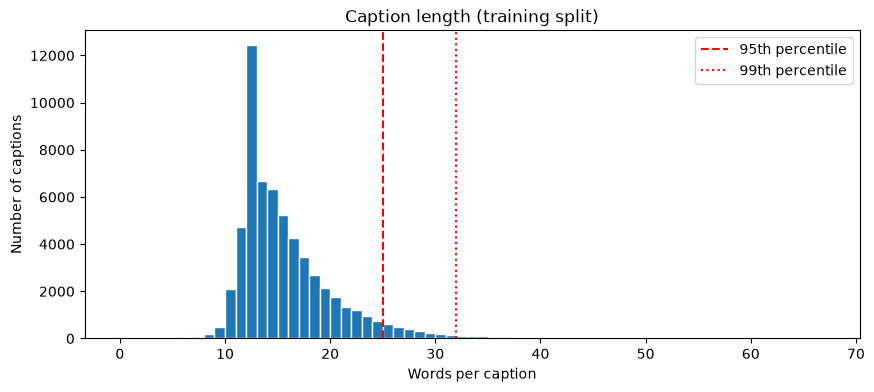

,max_words,captions_that_fit_%
0,15,63.96
1,20,87.88
2,25,95.94
3,30,98.64
4,40,99.81


In [11]:
lengths = train_caps["n_words"]

print(lengths.describe().round(2))
for q in [0.90, 0.95, 0.99]:
    print(f"{int(q * 100)}th percentile: {lengths.quantile(q):.0f} words")

plt.figure(figsize=(10, 4))
plt.hist(lengths, bins=range(0, lengths.max() + 2), edgecolor="white")
for q, style in [(0.95, "--"), (0.99, ":")]:
    plt.axvline(lengths.quantile(q), color="red", linestyle=style,
                label=f"{int(q * 100)}th percentile")
plt.title("Caption length (training split)")
plt.xlabel("Words per caption")
plt.ylabel("Number of captions")
plt.legend()
plt.show()

# How many captions fit without truncation for different maximum lengths
display(pd.DataFrame({
    "max_words": [15, 20, 25, 30, 40],
    "captions_that_fit_%": [
        round((lengths <= n).mean() * 100, 2) for n in [15, 20, 25, 30, 40]
    ],
}))

In [12]:
# Inspect the extremes: very short captions may be noise, very long ones may be merged captions
print("Shortest captions:")
for _, row in train_caps.nsmallest(10, "n_words").iterrows():
    print(f"  [{row['n_words']} words] {row['caption']!r}")

print("\nLongest captions:")
for _, row in train_caps.nlargest(5, "n_words").iterrows():
    print(f"  [{row['n_words']} words] {row['caption']!r}")

Shortest captions:
  [1 words] 'this'
  [3 words] 'the colorful bird'
  [4 words] 'a large black bird.'
  [5 words] 'this bird is all black.'
  [5 words] 'this bird is completely black.'
  [5 words] 'big bird with long neck,'
  [5 words] 'this bird is completely black.'
  [5 words] 'this bird is all black.'
  [5 words] 'this bird is completely black.'
  [5 words] 'white and has a yellowbill'

Longest captions:
  [66 words] "this special bird has a color of reddish-brown that tapers to the tail with a uniform gray-brown very smooth looking plumage, he has a black cheek patch and eyebrow with a tiny black beak and feet, and you can't help but notice the tuft of red to brown hair that sicks straight out off the back of his crown because he is beautiful."
  [66 words] 'this is a grayish bird with a stripe of black that extends from the top of its head through the eyes to the tip of the beak and down its neck along with a hint of white in the face, black, white, tan and pink wings, a black 

## 6. Vocabulary

Words that appear very rarely are often typos. A minimum frequency removes them (they become `<unk>`) and keeps the vocabulary small.

In [13]:
train_tokens = train_caps["caption"].map(tokenize)
word_counts = Counter(word for tokens in train_tokens for word in tokens)
total_tokens = sum(word_counts.values())

print("Total words (tokens):", total_tokens)
print("Unique words (vocabulary):", len(word_counts))

# Effect of a minimum-frequency threshold
rows = []
for min_freq in [1, 2, 3, 5, 10]:
    kept = {w: c for w, c in word_counts.items() if c >= min_freq}
    rows.append({
        "min_freq": min_freq,
        "vocab_size": len(kept),
        "tokens_covered_%": round(sum(kept.values()) / total_tokens * 100, 3),
    })
display(pd.DataFrame(rows))

Total words (tokens): 917573
Unique words (vocabulary): 4045


,min_freq,vocab_size,tokens_covered_%
0,1,4045,100.000
1,2,2196,99.798
2,3,1630,99.675
3,5,1237,99.528
4,10,874,99.263


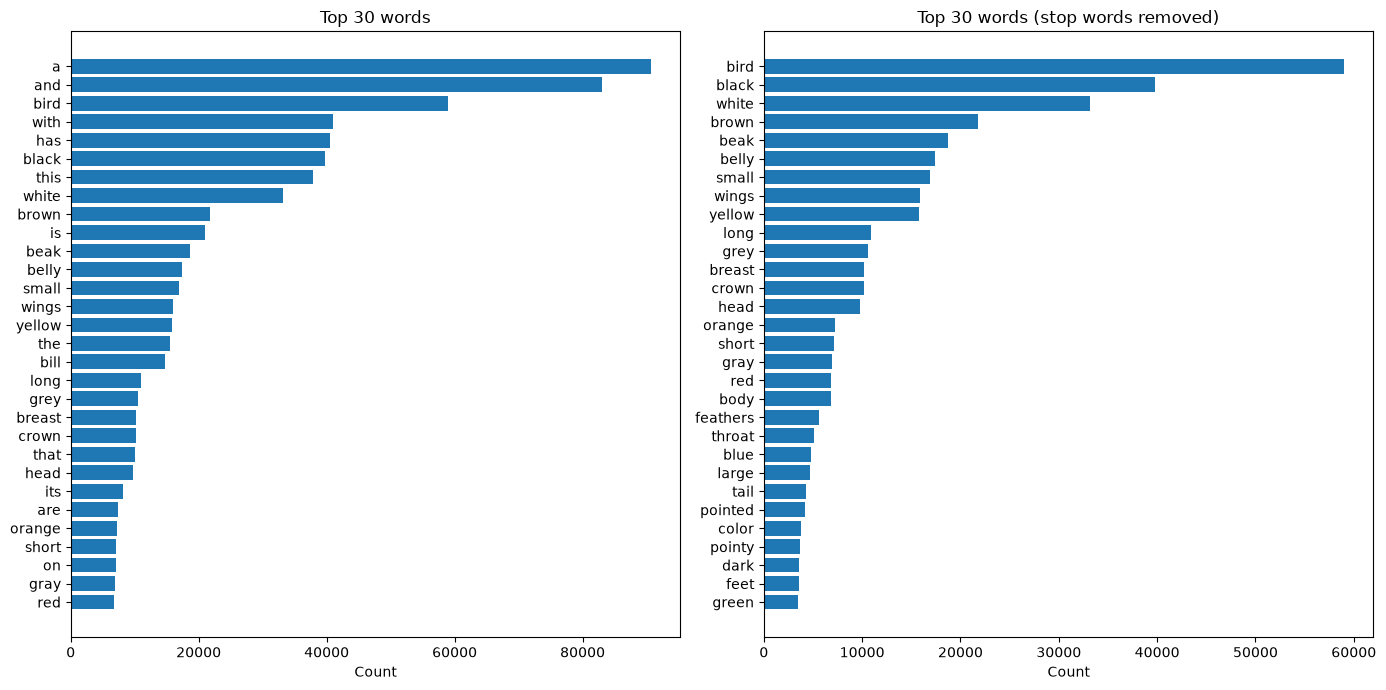

In [14]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

top_all = word_counts.most_common(30)
axes[0].barh([w for w, _ in top_all][::-1], [c for _, c in top_all][::-1])
axes[0].set_title("Top 30 words")

top_content = [
    (w, c) for w, c in word_counts.most_common() if w not in ENGLISH_STOP_WORDS
][:30]
axes[1].barh([w for w, _ in top_content][::-1], [c for _, c in top_content][::-1])
axes[1].set_title("Top 30 words (stop words removed)")

for ax in axes:
    ax.set_xlabel("Count")
plt.tight_layout()
plt.show()

In [15]:
# Rare words: check whether they are typos, real bird terms, or noise
rare_words = [w for w, c in word_counts.items() if c == 1]
print("Words that appear only once:", len(rare_words))

rng = np.random.default_rng(42)
print("\nRandom sample of 50:")
print(sorted(str(w) for w in rng.choice(rare_words, size=min(50, len(rare_words)), replace=False)))

print("\nCaptions containing a few of them:")
for word in rare_words[:5]:
    match = train_caps[train_tokens.map(lambda tokens: word in tokens)]
    print(f"  {word!r}: {match['caption'].iloc[0]!r}")

Words that appear only once: 1849

Random sample of 50:
[np.str_('amazingly'), np.str_('anbd'), np.str_('asia'), np.str_('astriped'), np.str_('attaches'), np.str_('birt'), np.str_('blu'), np.str_('blur'), np.str_('breastss'), np.str_('browner'), np.str_('clue'), np.str_('colord'), np.str_('comically'), np.str_('complement'), np.str_('diffuse'), np.str_('distinctie'), np.str_('falls'), np.str_('fantail'), np.str_('ff'), np.str_('finish'), np.str_('glimmers'), np.str_('glow'), np.str_('heater'), np.str_('hip'), np.str_('host'), np.str_('might'), np.str_('miniscule'), np.str_('na'), np.str_('overly'), np.str_('recurved'), np.str_('roused'), np.str_('separative'), np.str_('sienna'), np.str_('slit'), np.str_('slivers'), np.str_('stalk'), np.str_('straw'), np.str_('surprisingly'), np.str_('swoop'), np.str_('tanish'), np.str_('thickb'), np.str_('towhee'), np.str_('triagles'), np.str_('undercarriage'), np.str_('variously'), np.str_('vidid'), np.str_('winks'), np.str_('work'), np.str_('yellowbr

## 7. Unknown words in the test split

How many test words would become `<unk>` with a vocabulary built from training captions only.

In [16]:
MIN_FREQ = 5  # change after looking at the table in section 6
vocab = {w for w, c in word_counts.items() if c >= MIN_FREQ}

test_word_counts = Counter(
    word for tokens in test_caps["caption"].map(tokenize) for word in tokens
)
test_total = sum(test_word_counts.values())
unknown = {w: c for w, c in test_word_counts.items() if w not in vocab}

print(f"Vocabulary size (min_freq={MIN_FREQ}):", len(vocab))
print("Test tokens that would be <unk>:",
      f"{sum(unknown.values()) / test_total * 100:.2f}%")
print("Most common unknown test words:",
      Counter(unknown).most_common(20))

Vocabulary size (min_freq=5): 1237
Test tokens that would be <unk>: 0.53%
Most common unknown test words: [('trimmed', 16), ('super', 15), ('offset', 13), ('wingspans', 13), ('faced', 12), ('interspersed', 12), ('resting', 11), ('elegant', 10), ('blackened', 10), ('texture', 10), ('together', 10), ('predominant', 9), ('facing', 9), ('possessing', 9), ('tapers', 9), ('indigo', 9), ('especially', 9), ('undersides', 9), ('male', 9), ('blunted', 8)]


## 8. Duplicates and suspicious captions

In [17]:
print("Empty captions:", (train_caps["n_words"] == 0).sum())
print("Very short captions (3 words or fewer):", (train_caps["n_words"] <= 3).sum())

normalized = train_caps["caption"].map(lambda c: " ".join(tokenize(c)))
print("Duplicate captions within the same image:",
      train_caps.assign(norm=normalized).duplicated(["index", "norm"]).sum())

print("\nCaptions repeated most often across different images:")
display(
    normalized.value_counts().head(10).rename_axis("caption").reset_index(name="count")
)

Empty captions: 0
Very short captions (3 words or fewer): 2
Duplicate captions within the same image: 641

Captions repeated most often across different images:


,caption,count
0,this bird has wings that are brown and has a w...,601
1,this bird has wings that are black and has a w...,446
2,this bird has a speckled belly and breast with...,288
3,this bird has wings that are grey and has a wh...,255
4,this bird is brown with white and has a very s...,218
5,this bird has wings that are black and has a y...,198
6,this bird is brown with white and has a long p...,176
7,this bird is black with white and has a long p...,157
8,this bird has wings that are black and has a t...,129
9,this bird is white with black and has a long p...,114


## 9. Color words

Color words matter for both captioning and colorization: they show which colors the captions describe most.

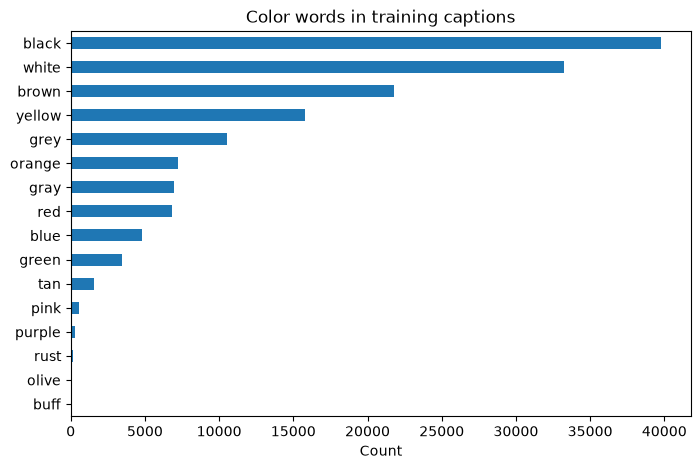

Note: 'gray' and 'grey' are the same color and could be merged during cleaning.


In [18]:
color_words = [
    "black", "white", "brown", "gray", "grey", "yellow", "red", "orange",
    "blue", "green", "tan", "buff", "olive", "pink", "purple", "rust",
]
color_counts = pd.Series(
    {c: word_counts.get(c, 0) for c in color_words}
).sort_values()

color_counts.plot.barh(figsize=(8, 5), title="Color words in training captions")
plt.xlabel("Count")
plt.show()

print("Note: 'gray' and 'grey' are the same color and could be merged during cleaning.")

## Caption EDA: findings and decisions

| Question | Finding | Decision |
|---|---|---|
| Captions per image | Every image has exactly 10 captions: 59,940 training and 57,940 test captions. Each `description` ends with a trailing `\n`. | Split on `\n` and drop empty pieces. No images need to be removed. |
| Casing | No uppercase letters (0 captions). | Lowercase anyway, as a safety step. |
| Punctuation | Commas in 47.5% of captions; only 77.6% end with a period (inconsistent). Also `- ' / ; & " ( ) : ! ?`. Hyphens join words (`reddish-brown`, `yellow-tipped`). | Replace every non-letter character with a space, so `reddish-brown` becomes `reddish brown`. |
| Corrupted characters | 848 `�` (Unicode replacement character, U+FFFD) in 27 captions, standing in for spaces: `this��bird��has…`. | Replace with a space, **not** delete, or words merge (`thisbird`). |
| Apostrophes | 1,690 (`bird's`, `it's`, `can't`). Splitting on them creates a fake token `s` (1,639 times). | Delete apostrophes before the space rule: `bird's` becomes `birds`, `it's` becomes `its`. |
| Digits | 65 captions (0.11%), mostly counts: `1 wingbar`, `2 white wing bars`. | Convert digits to words (`2` becomes `two`). |
| Spelling variants | `grey` 10,563 vs `gray` 6,953; `greyish` 135 vs `grayish` 207; `coloured` 4 vs `colored` 2,083. | Merge to one spelling: `gray` to `grey`, `grayish` to `greyish`, `coloured` to `colored`. |
| Caption length | Mean 15.3 words, median 14, max 66. 95th percentile 25, 99th percentile 32. 98.64% have 30 words or fewer. | Max 30 words, so the sequence length is 32 with `<start>`/`<end>`. Drop training captions longer than 30 words (about 1.4%); their images keep their other captions. |
| Vocabulary and rare words | 917,573 tokens, 4,045 unique words. 1,849 appear only once: mostly typos (`anbd`, `birt`, `breastss`, `vidid`) or merged words (`agrayish`, `yellowbreast`), plus a few real rare words (`towhee`, `sienna`). | `min_freq = 5`: 1,237 words + 4 special tokens (`<pad> <start> <end> <unk>`), covering 99.53% of training tokens. Build the vocabulary from **training captions only**. |
| Test `<unk>` rate | With `min_freq = 5`, 0.53% of test tokens become `<unk>`. They are real but rare words (`trimmed`, `indigo`, `male`). | Acceptable, which confirms `min_freq = 5`. |
| Empty / very short captions | 0 empty. 2 captions with 3 words or fewer: `this` and `the colorful bird`. | Drop captions with fewer than 3 words (removes `this`). |
| Duplicates within an image | 641 exact duplicates inside the same image's 10 captions. | Remove them from the training set. |
| Repeated (template-like) captions | 11,176 captions (18.6%) appear more than once across images. The most common, `this bird has wings that are brown and has a white belly`, appears 601 times across 92 species. | Keep them (they are valid descriptions), but expect the model to favor these generic sentences; check caption diversity during evaluation. |
| Noisy / wrong captions | Some captions are wrong or off-topic, e.g. `brown duck playing on the lake making a poodle` (an albatross, and a typo for "puddle"). | Cannot be fixed by hand at this scale. Keep them; rare typos become `<unk>`. Mention the noise in the report. |

The same cleaning is applied to the test captions, but the test split is never used to build the vocabulary or choose settings.